# 11 — Supervised Fine-Tuning (SFT)

## Terms & Definitions
- **Supervised fine-tuning (SFT)**: training a pretrained model on (instruction, response) pairs so it learns to behave like an assistant that responds to instructions, rather than just continuing arbitrary text.
- **Prompt masking**: computing the training loss *only* on the response tokens, not the instruction tokens — so the model isn't penalized for "failing to predict" the instruction (which it's given, not generating) and instead focuses entirely on learning to produce good responses.
- **Instruction tuning**: the general practice of adapting a pretrained model toward following instructions via SFT — the term used broadly across GPT/InstructGPT/Llama-style pipelines.

## Why Pretraining Alone Isn't Enough
A pretrained model (notebook 08) has learned "what plausible text looks like" for its training corpus. But if you give it a prompt like `"What is a battery?"`, a pure pretrained model has no particular reason to *answer the question* — it just continues the text in whatever way is statistically most similar to what followed similar text during pretraining, which could be almost anything (more questions, an unrelated paragraph, etc.).

SFT explicitly teaches the format: "when text looks like an instruction, the right continuation is a helpful response to it." This is done by training on curated (instruction, response) examples, using the same next-token-prediction mechanism as before — SFT is not a new training algorithm, just a new *dataset and loss-masking scheme* layered onto the exact same loop.

## History
"Instruction tuning" as a distinct step was popularized by papers like **InstructGPT** (Ouyang et al., 2022, the direct ancestor of ChatGPT) — showing that a relatively small amount of high-quality demonstration data, layered on top of large-scale pretraining, dramatically improved a model's ability to follow instructions and be genuinely useful, even before RLHF was applied. Every major assistant-style LLM (GPT-4, Claude, Llama, Gemini) uses some form of SFT.

## The Key Mechanic: Prompt Masking

Recall `InstructionDataset` in `src/data.py`, used below. For each example, the tokenized sequence looks like:

```
### Instruction:\n{instruction}\n### Response:\n{response}
```

We compute cross-entropy loss (notebook 04) as usual, but set the target label to `-100` (PyTorch's `ignore_index` for `F.cross_entropy`) at every position that falls within the instruction/prompt portion. Concretely:

- Tokens that are part of `### Instruction:\n{instruction}\n### Response:\n` → label = `-100` (ignored, no gradient from these positions)
- Tokens that are part of `{response}` → label = the actual next token (real training signal)

This way, gradients only ever push the model to get better at *generating responses*, never at "predicting" the instruction it was already given.


In [1]:
import sys
sys.path.insert(0, "..")

import time
import torch
from torch.utils.data import DataLoader

from src.model import GPTMicro, GPTConfig
from src.data import train_bpe_tokenizer, load_electricity_for_boys, InstructionDataset, set_seed
from src.train_utils import get_lr, save_checkpoint, load_checkpoint, plot_losses

torch.set_num_threads(6)
set_seed(1337)


## Load the CPT Checkpoint and Instruction Dataset


In [2]:
config = GPTConfig(vocab_size=8000, block_size=128, n_layer=6, n_head=8, n_embd=480, dropout=0.1)
model = GPTMicro(config)
load_checkpoint(model, "cpt_electricity", device="cpu")
print(f"loaded cpt_electricity checkpoint ({model.num_params()/1e6:.2f}M params)")

text = load_electricity_for_boys()
tokenizer = train_bpe_tokenizer(text, vocab_size=8000)

dataset = InstructionDataset("../data/instruction_data.jsonl", tokenizer, block_size=config.block_size)
print(f"instruction dataset: {len(dataset)} examples")


loaded cpt_electricity checkpoint (20.53M params)



instruction dataset: 1000 examples


## Inspect Prompt Masking on One Example

Let's confirm the masking actually does what we described -- print the decoded input alongside which positions are masked (`-100`) vs. real training targets.


In [3]:
input_ids, labels = dataset[0]

print("full input text:")
print(repr(tokenizer.decode([t for t in input_ids.tolist() if t != tokenizer.token_to_id('<pad>')])))
print()

n_masked = (labels == -100).sum().item()
n_total = len(labels)
print(f"{n_masked}/{n_total} label positions are masked (-100 = ignored in loss)")
print()

# Show which tokens correspond to real (unmasked) training targets.
real_target_ids = [t.item() for t in labels if t.item() != -100]
print("tokens the model actually gets loss signal for (the response):")
print(repr(tokenizer.decode(real_target_ids)))


full input text:
" Instruction:\nConvert 'current' to title case.\n Response:\n"

127/128 label positions are masked (-100 = ignored in loss)

tokens the model actually gets loss signal for (the response):
'Current'


## Fine-Tuning Loop

Same shape as before, but now iterating over instruction examples via a `DataLoader`, and `targets` already has `-100` baked in at the masked positions -- `F.cross_entropy`'s `ignore_index=-100` (see `src/model.py: GPTMicro.forward`) handles the rest automatically.


In [4]:
batch_size = 16
n_epochs = 3
max_lr = 5e-5   # lower still than CPT -- SFT makes more targeted, smaller updates
warmup_steps = 20

loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
n_steps = len(loader) * n_epochs
optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=0.01)

print(f"training for {n_epochs} epochs x {len(loader)} batches/epoch = {n_steps} total steps")


training for 3 epochs x 63 batches/epoch = 189 total steps


In [5]:
train_losses = []
step = 0
t0 = time.time()

for epoch in range(n_epochs):
    for input_ids, labels in loader:
        lr = get_lr(step, warmup_steps, n_steps, max_lr)
        for g in optimizer.param_groups:
            g["lr"] = lr

        logits, loss = model(input_ids, targets=labels)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_losses.append(loss.item())
        step += 1

    print(f"epoch {epoch+1}/{n_epochs}  last_loss {loss.item():.3f}  ({time.time()-t0:.0f}s elapsed)")

print(f"\nSFT complete in {time.time()-t0:.0f}s")


epoch 1/3  last_loss 1.097  (72s elapsed)
epoch 2/3  last_loss 0.694  (132s elapsed)
epoch 3/3  last_loss 0.443  (196s elapsed)

SFT complete in 196s


epoch 2/3  last_loss 0.694  (129s elapsed)


epoch 3/3  last_loss 0.443  (194s elapsed)

SFT complete in 194s


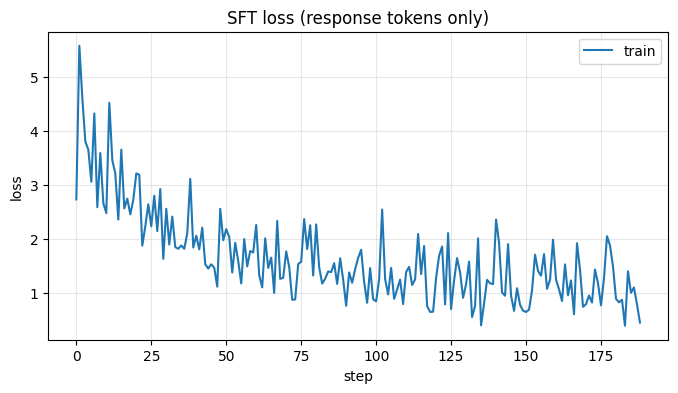

In [6]:
plot_losses(train_losses, title="SFT loss (response tokens only)")


In [7]:
path = save_checkpoint(model, "sft_electricity")
print(f"saved checkpoint to {path}")


saved checkpoint to /home/tyrel/projects/llm-lessons/checkpoints/sft_electricity.pt


## Compare Pre/Post-SFT Generations

This is the moment to see instruction-following behavior actually emerge. We generate from the same toy-task prompts using the CPT checkpoint (before SFT) and the new SFT checkpoint (after), using the same `### Instruction:\n...\n### Response:\n` format the model was trained on.


In [8]:
cpt_model = GPTMicro(config)
load_checkpoint(cpt_model, "cpt_electricity", device="cpu")
cpt_model.eval()
model.eval()

test_prompts = [
    "What is 12 + 7?",
    "Convert 'circuit' to uppercase.",
    "What is a battery used for?",
]

for prompt in test_prompts:
    formatted = InstructionDataset.PROMPT_TEMPLATE.format(instruction=prompt)
    context = torch.tensor([tokenizer.encode(formatted).ids], dtype=torch.long)

    torch.manual_seed(0)
    before = cpt_model.generate(context, max_new_tokens=20, temperature=0.7, top_k=20)
    torch.manual_seed(0)
    after = model.generate(context, max_new_tokens=20, temperature=0.7, top_k=20)

    print(f"PROMPT: {prompt}")
    print(f"  BEFORE SFT: {tokenizer.decode(before[0].tolist())!r}")
    print(f"  AFTER  SFT: {tokenizer.decode(after[0].tolist())!r}")
    print()


PROMPT: What is 12 + 7?
  BEFORE SFT: ' Instruction:\nWhat is 12 + 7?\n Response:\nWhat is an electromagnet? A material,\nWhat is a magnetic field when electric current flows'
  AFTER  SFT: ' Instruction:\nWhat is 12 + 7?\n Response:\n66N7505665\n772543940'

PROMPT: Convert 'circuit' to uppercase.
  BEFORE SFT: " Instruction:\nConvert 'circuit' to uppercase.\n Response:\nWhat is an electromagnet? A dynamo is\nWhat is a material, such as copper,"
  AFTER  SFT: " Instruction:\nConvert 'circuit' to uppercase.\n Response:\nInsulshopNatorGshop' to differentcorded electrical observations.\nSator"

PROMPT: What is a battery used for?
  BEFORE SFT: ' Instruction:\nWhat is a battery used for?\n Response:\nWhat is an electromagnet? A material,\nWhat is a magnetic field when electric current flows'
  AFTER  SFT: ' Instruction:\nWhat is a battery used for?\n Response:\nA battery stores chemical energy and converts it into electric current.\nA battery stores electric'



PROMPT: Convert 'circuit' to uppercase.
  BEFORE SFT: " Instruction:\nConvert 'circuit' to uppercase.\n Response:\nWhat is an electromagnet? A dynamo is\nWhat is a material, such as copper,"
  AFTER  SFT: " Instruction:\nConvert 'circuit' to uppercase.\n Response:\nInsulshopNatorGshop' to differentcorded electrical observations.\nSator"



PROMPT: What is a battery used for?
  BEFORE SFT: ' Instruction:\nWhat is a battery used for?\n Response:\nWhat is an electromagnet? A material,\nWhat is a magnetic field when electric current flows'
  AFTER  SFT: ' Instruction:\nWhat is a battery used for?\n Response:\nA battery stores chemical energy and converts it into electric current.\nA battery stores electric'



Look for the SFT model producing shorter, more direct completions that resemble actual answers (even if not always numerically/factually correct at this tiny scale) — while the pre-SFT model is more likely to trail off into unrelated continuation text, since it was never taught the instruction/response *format* specifically.

## Exercise
Try increasing `n_epochs` and see whether the SFT model's answers become more consistently well-formatted (even if not more *correct* — correctness on arithmetic specifically is a hard task for a model this small, and we'll partially address the "prefer better answers" problem next with reward modeling and RL).

## Summary
- SFT trains on (instruction, response) pairs using the *same* next-token loss as pretraining, but masks the loss so gradients only come from response tokens (`src/data.py: InstructionDataset`).
- This is what teaches a pretrained model to behave like it's responding to instructions, rather than just continuing arbitrary text.
- We saved this stage's result as the `sft_electricity` checkpoint — the base every RLHF notebook builds on.

Next: **12 — Reward Modeling** (teaching a model to score *how good* a response is, using preference pairs — the first half of RLHF).
